# Previsão de Manutenção

Projeto avaliativo do Módulo 1: prever falhas mecânicas (falha_maquina) a partir de dados de sensores.

## Fase 1: Análise Exploratória (EDA)

### Importação das bibliotecas e dados

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Gráfico com fundo claro e grade
sns.set_theme(style="whitegrid")

In [28]:
# Caminho do arquivo CSV
caminho = 'D:/Cursos/SCTEC/Carreira Tech/Módulo 1/Projeto Final/data/manutencao_preditiva.csv'

df = pd.read_csv(caminho)
df.head()

,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0


### 1.1 Dimensões, tipos de dados e resumo estatístico

In [29]:
linhas, colunas = df.shape
print(f"O dataset possui {linhas} linhas e {colunas} colunas.")

O dataset possui 10000 linhas e 14 colunas.


In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   udi                      10000 non-null  int64  
 1   id_produto               10000 non-null  str    
 2   tipo                     10000 non-null  str    
 3   temperatura_ar_k         9500 non-null   float64
 4   temperatura_processo_k   9500 non-null   float64
 5   velocidade_rotacao_rpm   9500 non-null   float64
 6   torque_nm                9500 non-null   float64
 7   desgaste_ferramenta_min  10000 non-null  int64  
 8   falha_maquina            10000 non-null  int64  
 9   falha_twf                10000 non-null  int64  
 10  falha_hdf                10000 non-null  int64  
 11  falha_pwf                10000 non-null  int64  
 12  falha_osf                10000 non-null  int64  
 13  falha_rnf                10000 non-null  int64  
dtypes: float64(4), int64(8), str(2)
me

In [31]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
udi,10000.0,5000.500000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
temperatura_ar_k,9500.0,300.002158,2.001689,295.3,298.30,300.1,301.50,304.5
temperatura_processo_k,9500.0,310.000895,1.486432,305.7,308.80,310.1,311.10,313.8
velocidade_rotacao_rpm,9500.0,1539.245263,180.273589,1168.0,1423.00,1504.0,1613.00,2886.0
torque_nm,9500.0,39.974168,9.995453,3.8,33.10,40.1,46.70,76.6
desgaste_ferramenta_min,10000.0,107.951000,63.654147,0.0,53.00,108.0,162.00,253.0
falha_maquina,10000.0,0.033900,0.180981,0.0,0.00,0.0,0.00,1.0
falha_twf,10000.0,0.004600,0.067671,0.0,0.00,0.0,0.00,1.0
falha_hdf,10000.0,0.011500,0.106625,0.0,0.00,0.0,0.00,1.0
falha_pwf,10000.0,0.009500,0.097009,0.0,0.00,0.0,0.00,1.0


#### Observações gerais

- **Valores ausentes:** as colunas `temperatura_ar_k`, `temperatura_processo_k`, `velocidade_rotacao_rpm` e `torque_nm` têm 9.500 valores preenchidos em 10.000 linhas (conforme `info()` e o `count` do `describe()`), ou seja, 500 valores ausentes (`NaN`), 5%, em cada uma delas. As demais colunas estão completas.
- **Variável alvo desbalanceada:** a média de `falha_maquina` é 0,0339, pois a coluna só tem 0 e 1. Isso significa que 3,39% das máquinas falharam e 96,61% operaram normalmente. Um modelo que sempre previsse "sem falha" iria acertar 96,61%, então vai ser preciso balancear os dados de treino
- **Possíveis outliers:** em `velocidade_rotacao_rpm` o máximo (2886) está muito acima do percentil 75 (1613) e a cerca de 7,5 desvios padrão da média (1539). Os boxplots da Fase 2 vão confirmar isso.

### 1.2 Gráficos analíticos

#### Gráfico 1: distribuição da variável alvo

falha_maquina
0    9661
1     339
Name: count, dtype: int64
falha_maquina
0    96.61
1     3.39
Name: proportion, dtype: float64


C:\Users\Arthur\AppData\Local\Temp\ipykernel_21880\2621147450.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="falha_maquina", data=df, palette="Set2")


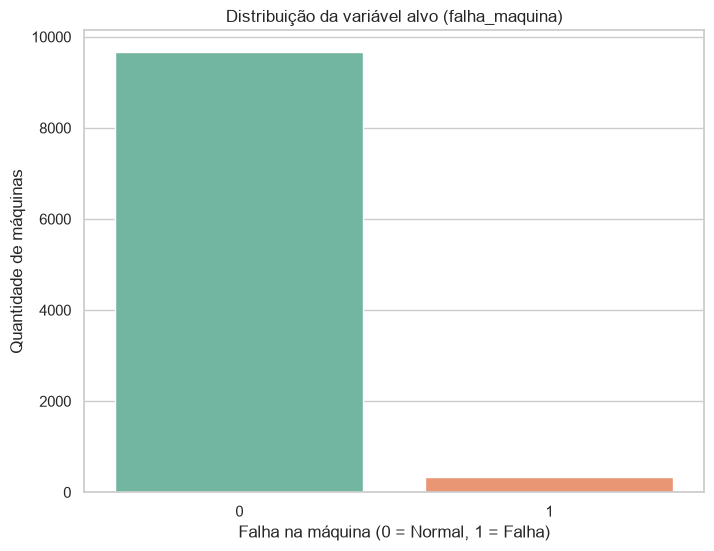

In [32]:
#Quantidade e porcentagem de cada classe
print(df["falha_maquina"].value_counts())
print((df["falha_maquina"].value_counts(normalize=True)*100).round(2))

#Gráfico de barras
plt.figure(figsize=(8, 6))
sns.countplot(x="falha_maquina", data=df, palette="Set2")
plt.title("Distribuição da variável alvo (falha_maquina)")
plt.xlabel("Falha na máquina (0 = Normal, 1 = Falha)")
plt.ylabel("Quantidade de máquinas")
plt.show()

#### Gráfico 2: distribuição das variáveis preditoras

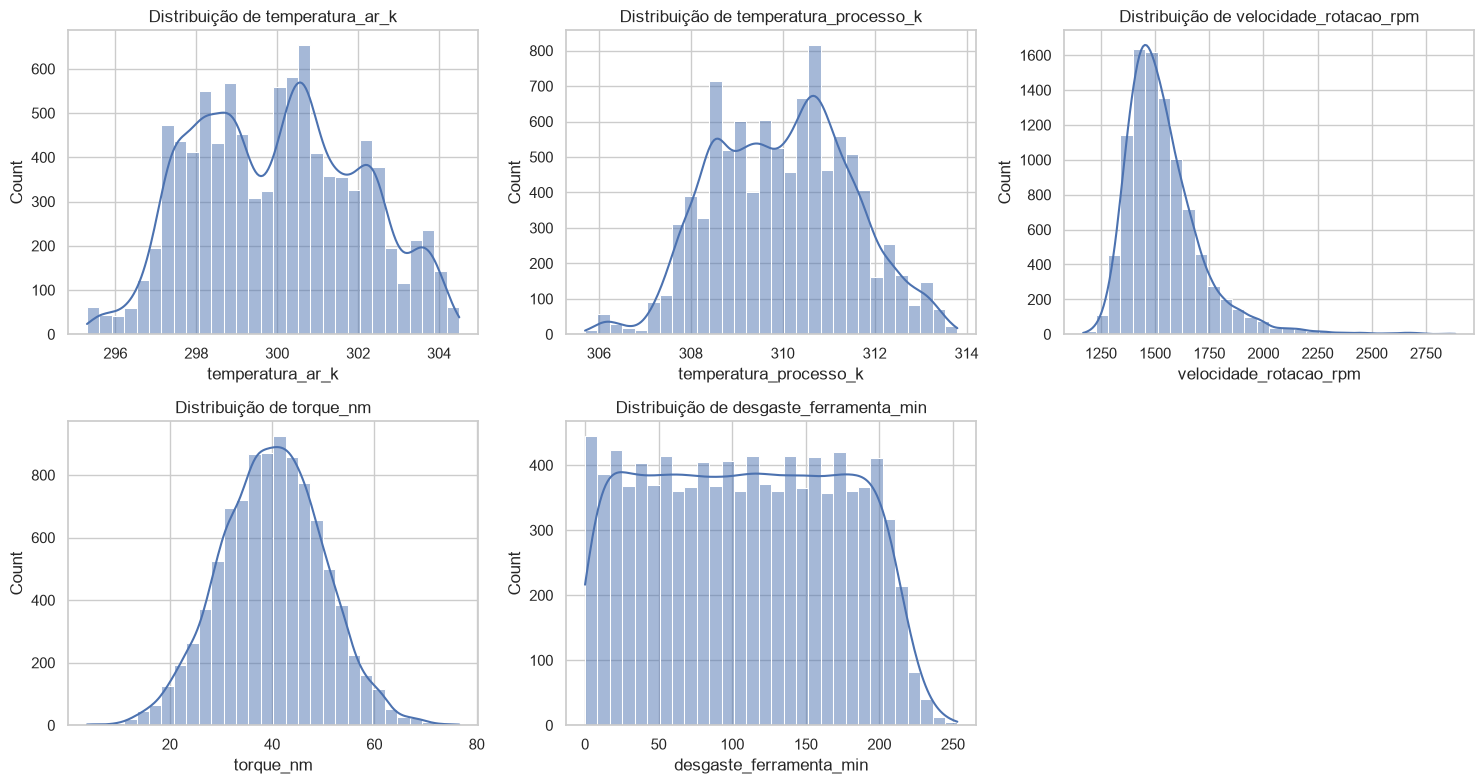

In [33]:
variaveis_numericas = ['temperatura_ar_k', 
'temperatura_processo_k', 'velocidade_rotacao_rpm',
'torque_nm', 'desgaste_ferramenta_min']

# Grade de 2 linhas x 3 colunas de gráficos
fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
eixos = eixos.flatten()

for eixo, coluna in zip(eixos, variaveis_numericas):
    sns.histplot(data=df, x=coluna, kde=True, bins=30, ax=eixo)
    eixo.set_title(f"Distribuição de {coluna}")

eixos[5].axis("off")

plt.tight_layout()
plt.show()

#### Gráfico 3: mapa de calor da correlação de Pearson

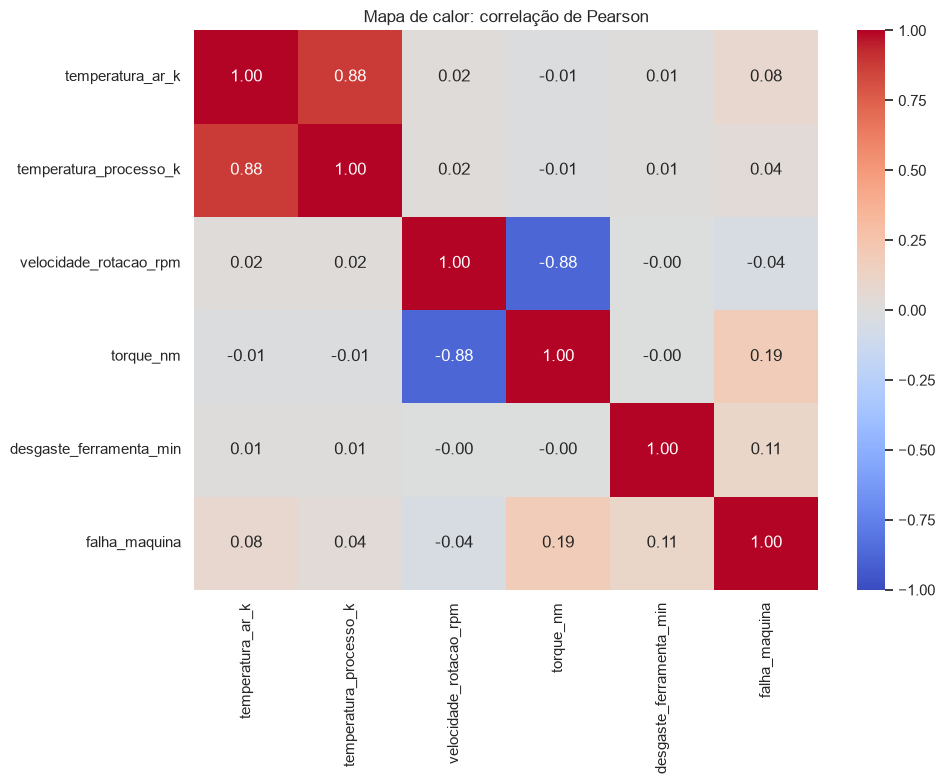

In [34]:
colunas_corr = ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm',
'torque_nm', 'desgaste_ferramenta_min', 'falha_maquina']

correlacao = df[colunas_corr].corr(method='pearson')

plt.figure(figsize=(10, 8))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,center=0)
plt.title("Mapa de calor: correlação de Pearson")
plt.tight_layout()
plt.show()

### 1.3 Análise da EDA

**Alvo desbalanceado:** a variável `falha_maquina` tem 9.661 ocorrências normais (96,61%) e apenas 339 falhas (3,39%). Com tão poucas falhas, um modelo pode acertar mais de 96% das previsões apenas respondendo "sem falha" sempre e mesmo assim não detectar as falhas, que são o objetivo do projeto. Por isso a acurácia sozinha pode enganar. Portanto, é importante dividir treino e teste com `stratify=y`, para manter a proporção de falhas nos dois conjuntos, e balancear somente os dados de treino (Fase 4).

**Forma das distribuições:** o `torque_nm` é a variável que mais se aproxima de uma distribuição normal (formato de sino, média 39,97 e mediana 40,1). As duas temperaturas têm formato parecido entre si, o que pode ser explicado pela correlação alta entre elas. A `velocidade_rotacao_rpm` é assimétrica, com cauda longa à direita (média 1539 acima da mediana 1504 e máximo de 2886), o que indica possíveis outliers e sugere que a mediana pode ser mais adequada que a média para preencher seus valores ausentes. O `desgaste_ferramenta_min` se distribui de forma quase uniforme entre 0 e cerca de 200 minutos.

**Correlações:** no mapa de calor, `temperatura_ar_k` e `temperatura_processo_k` têm correlação forte e positiva (0,88), ou seja, carregam informação parecida. `torque_nm` e `velocidade_rotacao_rpm` têm correlação forte e negativa (−0,88), o que é esperado, pois a potência é o produto do torque pela velocidade, quando a velocidade sobe o torque tende a cair. Isso sugere criar a variável `potencia` na Fase 3. Em relação ao alvo, as correlações são fracas (no máximo 0,19, com o torque), então nenhuma variável isolada explica as falhas. Como a correlação de Pearson mede apenas relações lineares, as falhas podem depender de combinações de variáveis.

**Colunas que ficam fora do X:** as colunas `falha_twf`, `falha_hdf`, `falha_pwf`, `falha_osf` e `falha_rnf` indicam o motivo da quebra e só são conhecidas depois que ela acontece; usá-las como preditoras causaria vazamento de dados (data leakage), e as anotações da engenharia não permitem isso. `udi` e `id_produto` são apenas identificadores, sem relação com a falha. A coluna `tipo` (L, M, H) é texto e precisará ser convertida em número ou descartada nas próximas fases.

**Estratégia de modelagem:** na Fase 2, remover duplicados, preencher os 500 ausentes de cada coluna com média ou mediana conforme a distribuição e confirmar os outliers com boxplots. Na Fase 3, criar `potencia = velocidade_rotacao_rpm * torque_nm`. Na Fase 4, dividir 80/20 com `stratify=y` e balancear só o treino. Na avaliação, lembrar que a acurácia pode ser alta mesmo com o modelo errando as falhas.

## Fase 2: Limpeza e Tratamento de Dados (Data Prep)

### 2.1 Linhas duplicadas

In [35]:
print("Linhas duplicadas (todas as colunas):", df.duplicated().sum())
print("udi repetidos:", df["udi"].duplicated().sum())
print("id_produto repetidos:", df["id_produto"].duplicated().sum()) 

Linhas duplicadas (todas as colunas): 0
udi repetidos: 0
id_produto repetidos: 0


In [36]:
sem_ids = df.drop(columns=["udi", "id_produto"])
print("Duplicadas ignorando ids (todas as linhas):", sem_ids.duplicated().sum())
print("Duplicadas ignorando ids (só linhas completas):", sem_ids.dropna().duplicated().sum())

Duplicadas ignorando ids (todas as linhas): 185
Duplicadas ignorando ids (só linhas completas): 0


In [37]:
linhas_antes = len(df)
df = df.drop_duplicates()
print(f"Linhas antes: {linhas_antes} | Linhas depois: {len(df)} | Linhas removidas: {linhas_antes - len(df)}")

Linhas antes: 10000 | Linhas depois: 10000 | Linhas removidas: 0


**Conclusão:** não há linhas duplicadas. `df.duplicated()` retornou 0, e `udi` e `id_produto` também não se repetem. Como o `udi` é único comparar todas as colunas nunca encontraria duplicatas, então repeti a verificação ignorando os identificadores: nas linhas completas o resultado também foi 0. Os 185 casos que aparecem com as linhas incompletas são falsos, porque o pandas considera dois `NaN` iguais. Nenhuma linha foi removida.

### 2.2 Valores ausentes

In [38]:
colunas_sensores = ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm']

#Quantidade e procentagem de ausentes em todas as colunas
pd.DataFrame({
    "Ausentes": df.isnull().sum(),
    "Porcentagem (%)": (df.isnull().mean() * 100).round(2)
})

,Ausentes,Porcentagem (%)
udi,0,0.0
id_produto,0,0.0
tipo,0,0.0
temperatura_ar_k,500,5.0
temperatura_processo_k,500,5.0
velocidade_rotacao_rpm,500,5.0
torque_nm,500,5.0
desgaste_ferramenta_min,0,0.0
falha_maquina,0,0.0
falha_twf,0,0.0


In [39]:
# Verifica se os ausentes estão nas mesmas linhas
linhas_com_ausente = df[colunas_sensores].isnull().any(axis=1)
print("Linhas com algum ausente:", linhas_com_ausente.sum())
print("Linhas com os 4 sensores ausentes:", df[colunas_sensores].isnull().all(axis=1).sum())

# Taxa de falha nas linhas sem e com ausentes
df.groupby(linhas_com_ausente)["falha_maquina"].agg(["count", "sum", "mean"])

Linhas com algum ausente: 500
Linhas com os 4 sensores ausentes: 500


,count,sum,mean
False,9500,322,0.033895
True,500,17,0.034000


**Conclusão:** as quatro colunas de sensores tem 500 valores ausentes (5%) cada, e eles estão nas mesmas 500 linhas, nesses registros todos os sensores ficaram sem leitura. A taxa de falha dessas linhas (3,4%) é praticamente igual as outras (3,39%), então essa ausência não parece estar ligada à falha. Remover essas linhas descartaria 17 das 339 falhas, que já são poucas, por isso os valores vão ser imputados

### 2.3 Outliers (boxplots)

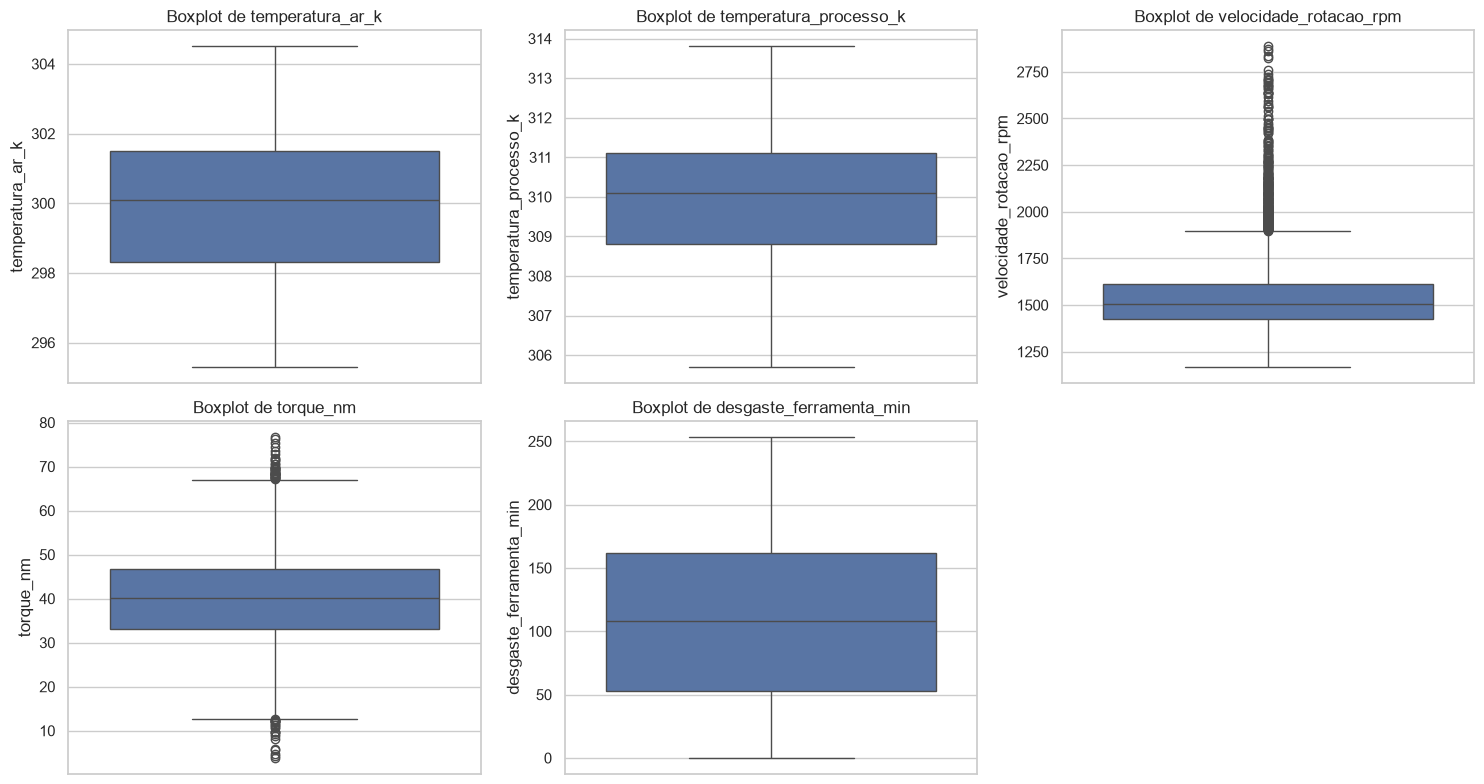

In [40]:
variaveis_numericas = [
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
    "desgaste_ferramenta_min",
]

fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
eixos = eixos.flatten()

for eixo, coluna in zip(eixos, variaveis_numericas):
    sns.boxplot(data=df, y=coluna, ax=eixo)
    eixo.set_title(f"Boxplot de {coluna}")

eixos[5].axis("off")
plt.tight_layout()
plt.show()

In [41]:
resumo = []
for coluna in variaveis_numericas:
    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr
    qtd = ((df[coluna] < limite_inf) | (df[coluna] > limite_sup)).sum()
    resumo.append({
        "coluna": coluna,
        "limite_inferior": round(limite_inf, 2),
        "limite_superior": round(limite_sup, 2),
        "outliers": qtd,
    })

pd.DataFrame(resumo)

,coluna,limite_inferior,limite_superior,outliers
0,temperatura_ar_k,293.50,306.30,0
1,temperatura_processo_k,305.35,314.55,0
2,velocidade_rotacao_rpm,1138.00,1898.00,398
3,torque_nm,12.70,67.10,63
4,desgaste_ferramenta_min,-110.50,325.50,0


**Conclusão:** os boxplots confirmam outliers em `velocidade_rotacao_rpm` (398 valores, todos acima de 1898) e em `torque_nm` (63 valores, acima de 67,1 e abaixo de 12,7). O limite inferior calculado para `desgaste_ferramenta_min` é negativo (−110,5) por efeito da fórmula do boxplot, porem nao existe minuto negativo, então o menor valor real é 0, dessa forma não é considerado que tenha outliers nessa variável. Também não há outliers nas temperaturas. Os outliers foram mantidos: podem representar condições reais de operação, inclusive próximas às falhas, e o enunciado pede apenas identificá-los. Remover esses registros poderia eliminar justamente os casos que o modelo precisa aprender

### 2.4 Imputação de valores ausentes

In [42]:
imputacao = {
    "temperatura_ar_k": "media",
    "temperatura_processo_k": "media",
    "torque_nm": "media",
    "velocidade_rotacao_rpm": "mediana",
}

for coluna, metodo in imputacao.items():
    valor = df[coluna].mean() if metodo == "media" else df[coluna].median()
    df[coluna] = df[coluna].fillna(valor)
    print(f"{coluna}: preenchido com a {metodo} = {valor:.2f}")

print("Ausentes restantes:", df.isna().sum().sum())

temperatura_ar_k: preenchido com a media = 300.00
temperatura_processo_k: preenchido com a media = 310.00
torque_nm: preenchido com a media = 39.97
velocidade_rotacao_rpm: preenchido com a mediana = 1504.00
Ausentes restantes: 0


**Justificativa:** para `temperatura_ar_k`, `temperatura_processo_k` e `torque_nm` a média e a mediana são praticamente iguais pois as distribuições são simétricas, então usei a média. Para `velocidade_rotacao_rpm` a distribuição é assimétrica, com cauda longa a direita e 398 outliers, a média (1539) é puxada pelos valores extremos e fica acima da mediana (1504). Por isso usei a mediana, que não é afetada pelos extremos. Depois da imputação não restaram valores ausentes

## Fase 3: Feature Engineering

Criação da variável `potencia = velocidade_rotacao_rpm * torque_nm`. A operação é feita depois da imputação (Fase 2), para não gerar valores nulos. O produto de rpm por N·m é proporcional a potência em watts (basta multiplicar por 2π/60), essa constante não altera o comportamento dos modelos

In [43]:
df["potencia"] = df["velocidade_rotacao_rpm"] * df["torque_nm"]

print("Valores nulos em potencia:", df["potencia"].isna().sum())
df[["velocidade_rotacao_rpm", "torque_nm", "potencia"]].head()

Valores nulos em potencia: 0


,velocidade_rotacao_rpm,torque_nm,potencia
0,1551.0,42.800000,66382.800000
1,1408.0,46.300000,65190.400000
2,1498.0,49.400000,74001.200000
3,1504.0,39.974168,60121.149305
4,1408.0,40.000000,56320.000000


In [44]:
df["potencia"].describe()

count    10000.000000
mean     59961.210585
std       9951.106738
min      10966.800000
25%      53497.050000
50%      60121.149305
75%      66412.975000
max      99980.400000
Name: potencia, dtype: float64

In [45]:
faixas = pd.qcut(
    df["potencia"],
    q=[0, 0.05, 0.25, 0.75, 0.95, 1],
    labels=["5% menores", "25% baixos", "50% centrais", "25% altos", "5% maiores"],
)
df.groupby(faixas, observed=True)["falha_maquina"].agg(["count", "sum", "mean"]).round(3)

,count,sum,mean
potencia,,,
5% menores,500,33,0.066
25% baixos,2000,15,0.008
50% centrais,5000,76,0.015
25% altos,2000,92,0.046
5% maiores,500,123,0.246


**Conclusão:** a coluna `potencia` foi criada sem valores nulos. A correlação linear dela com a falha (0,17) é fraca, mas a taxa de falha por faixa mostra que as falhas se concentram nos extremos: 24,6% entre os 5% de maior potência e 6,6% entre os 5% de menor potência, contra 1,5% na faixa central. A relação não é linear, por isso a correlação de Pearson foi subestima

## Fase 4: Divisão e Balanceamento dos Dados

### 4.1 Codificação da coluna tipo

In [46]:
mapa_tipo = {"L": 0, "M": 1, "H": 2}
df["tipo_cod"] = df["tipo"].map(mapa_tipo)

print("Valores nulos em tipo_cod:", df["tipo_cod"].isna().sum())
df.groupby("tipo")["falha_maquina"].agg(["count", "sum", "mean"]).round(4)

Valores nulos em tipo_cod: 0


,count,sum,mean
tipo,,,
H,1003,21,0.0209
L,6000,235,0.0392
M,2997,83,0.0277


**Decisão:** a coluna `tipo` (L, M, H) é texto e os modelos só aceitam números. Como as classes têm uma ordem (baixo, médio, alto), usei a codificação : L = 0, M = 1, H = 2. Mantive a coluna porque a taxa de falha muda com o tipo (L 3,92%, M 2,77%, H 2,09%)

### 4.2 Separação de X (preditoras) e y (alvo)

In [47]:
colunas_preditoras = [
    "tipo_cod",
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
    "desgaste_ferramenta_min",
    "potencia",
]

X = df[colunas_preditoras]
y = df["falha_maquina"]

print("Formato de X:", X.shape)
print("Formato de y:", y.shape)

Formato de X: (10000, 7)
Formato de y: (10000,)


**Colunas fora do X:** `udi` e `id_produto` (identificadores), `tipo` (substituída por `tipo_cod`), `falha_maquina` (alvo) e `falha_twf`, `falha_hdf`, `falha_pwf`, `falha_osf` e `falha_rnf` (indicam o motivo da falha e só são conhecidas depois dela, usar elas causaria vazamento de dados). A lista de preditoras foi escrita explicitamente pra nenhuma coluna proibida entrar por engano

### 4.3 Divisão treino (80%) e teste (20%)

In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Falhas no treino (%):", round(y_train.mean() * 100, 2))
print("Falhas no teste (%):", round(y_test.mean() * 100, 2))
print(y_train.value_counts())

Treino: (8000, 7) | Teste: (2000, 7)
Falhas no treino (%): 3.39
Falhas no teste (%): 3.4
falha_maquina
0    7729
1     271
Name: count, dtype: int64


**Justificativa:** dividi a base em 80% para treino e 20% para teste com `stratify=y`, isso mantem a proporção de falhas (cerca de 3,4%) nos dois conjuntos. Sem isso o teste poderia ficar com poucas falhas e a avaliação não seria confiável. Informei `random_state=42` para a divisão ser reproduzida

### 4.4 Balanceamento do treino com SMOTE

In [50]:
from imblearn.over_sampling import SMOTE

print("Treino antes do SMOTE:")
print(y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_smo, y_train_smo = smote.fit_resample(X_train, y_train)

print("\nTreino depois do SMOTE:")
print(y_train_smo.value_counts())
print("Formato de X_train_smo:", X_train_smo.shape)

print("\nTeste (intacto):")
print(y_test.value_counts())

Treino antes do SMOTE:
falha_maquina
0    7729
1     271
Name: count, dtype: int64

Treino depois do SMOTE:
falha_maquina
0    7729
1    7729
Name: count, dtype: int64
Formato de X_train_smo: (15458, 7)

Teste (intacto):
falha_maquina
0    1932
1      68
Name: count, dtype: int64


**Justificativa:** apliquei o smote só nos dados de treino que passaram de 7.729 normais e 271 falhas, para 7.729 de cada classe. O teste manteve a distribuição real (1.932 normais e 68 falhas), para medir o desempenho em condições reais. Se o smote fosse aplicado antes da divisão, exemplos sintéticos vazariam para o treino (data leakage)e iriam inflar a acurácia